In [1]:
import torch
import neck
import shutup; shutup.please()
import numpy as np
from pathlib import Path
neckruns = Path('/home/ubuntu/nfs/neckruns')
L = 16; tp=2

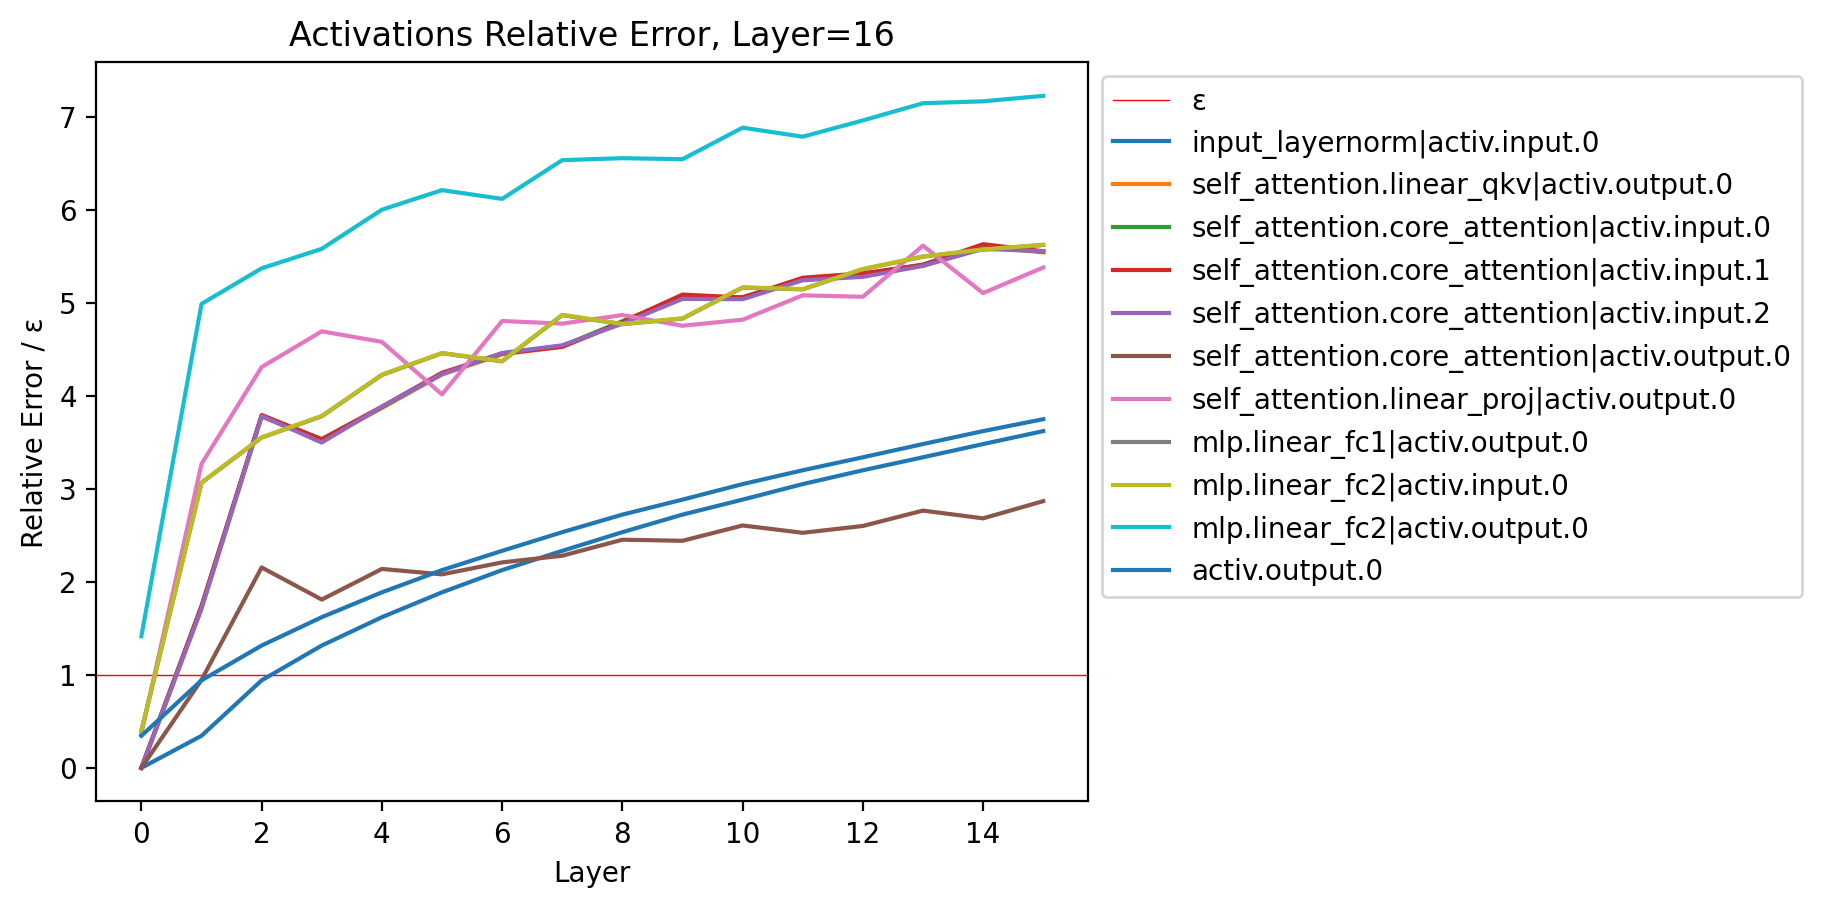

In [3]:
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp{tp}--llama-e4m3/activ.pt"), 4, L)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=1, color='r', linestyle='-', linewidth=0.5, label='ε')
# plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(L), rerr[1:].mean(axis=0)/bf16, label=k)
# label = "Err estimation: err=0.29*ε*L^(0.29)"
# plt.plot(range(L), np.maximum(0.29*(bf16)*np.arange(L)**(0.29), 0), label=label, linestyle='--')
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activations Relative Error, Layer={L}")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

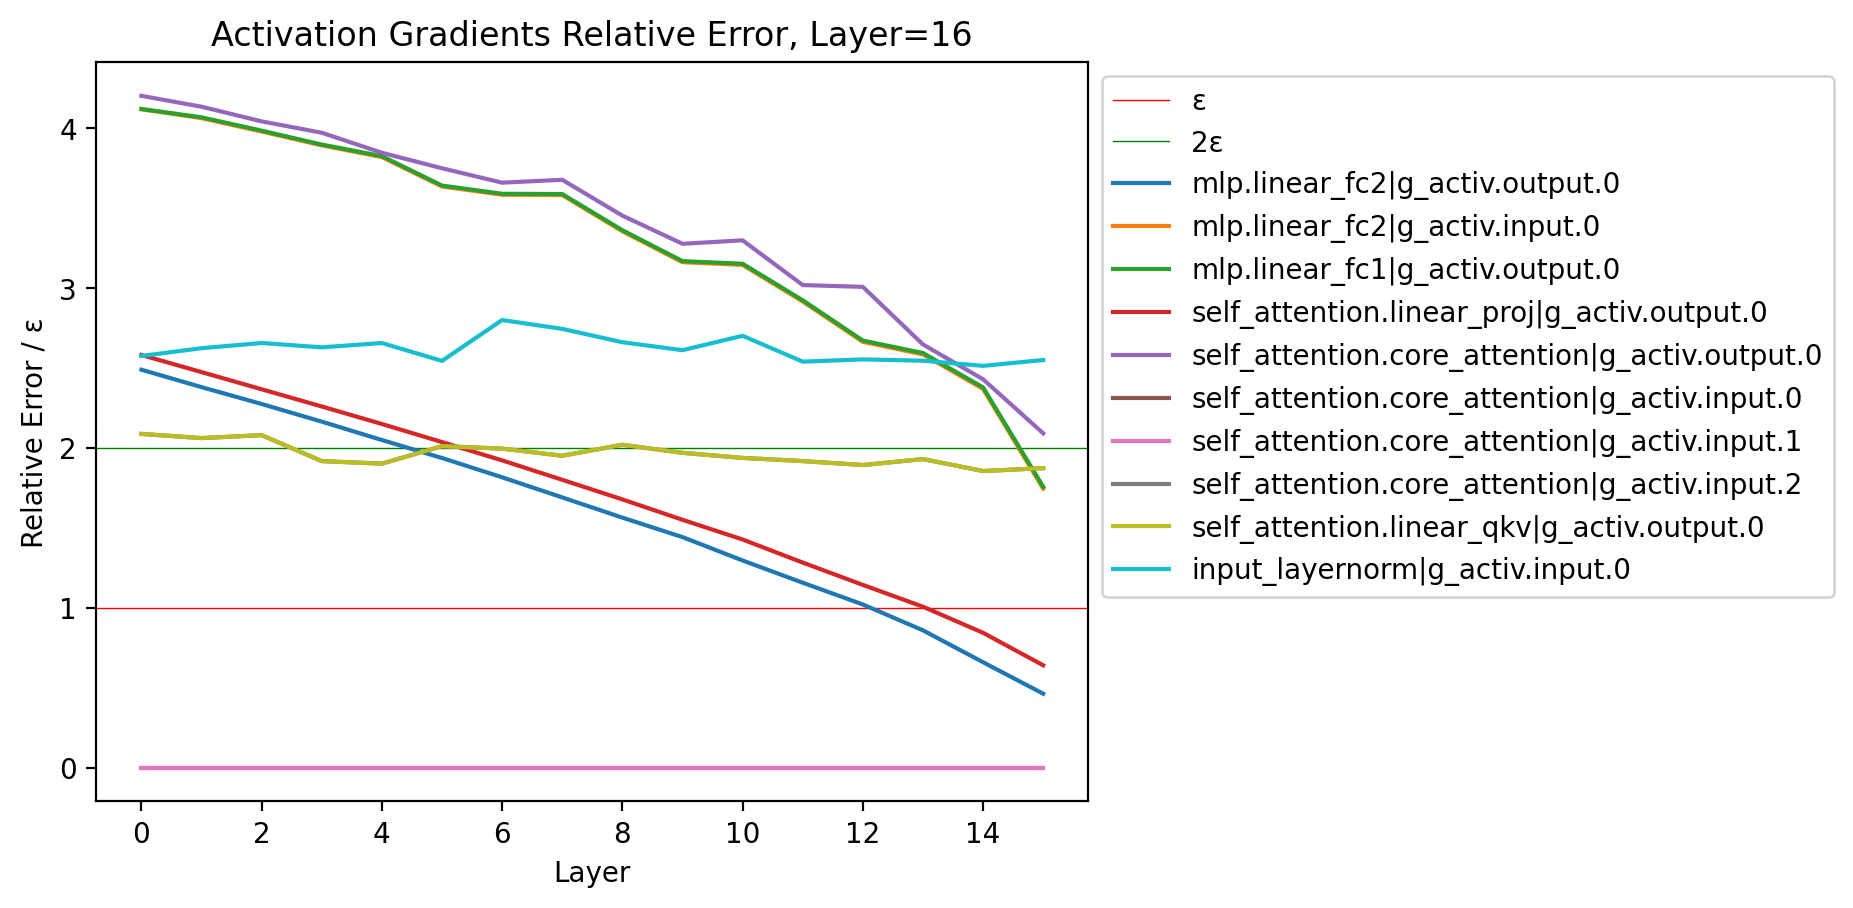

In [4]:
err_results = torch.load(neckruns/f"_single-v-tp{tp}--llama-e4m3/g_activ.pt")
for name, err in err_results.items():  # dQ, dK
    if err == 615.0:
        err_results[name] = 0.0
err_arr = neck.inspector.get_err_array(err_results, 4, L)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=1, color='r', linestyle='-', linewidth=0.5, label='ε')
plt.axhline(y=2, color='g', linestyle='-', linewidth=0.5, label='2ε')
for k, rerr in err_arr.items():
    plt.plot(range(L), rerr[1:].mean(axis=0)/bf16, label=k)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Activation Gradients Relative Error, Layer={L}")
plt.xlabel("Layer")
plt.ylabel("Relative Error / ε")
plt.show()

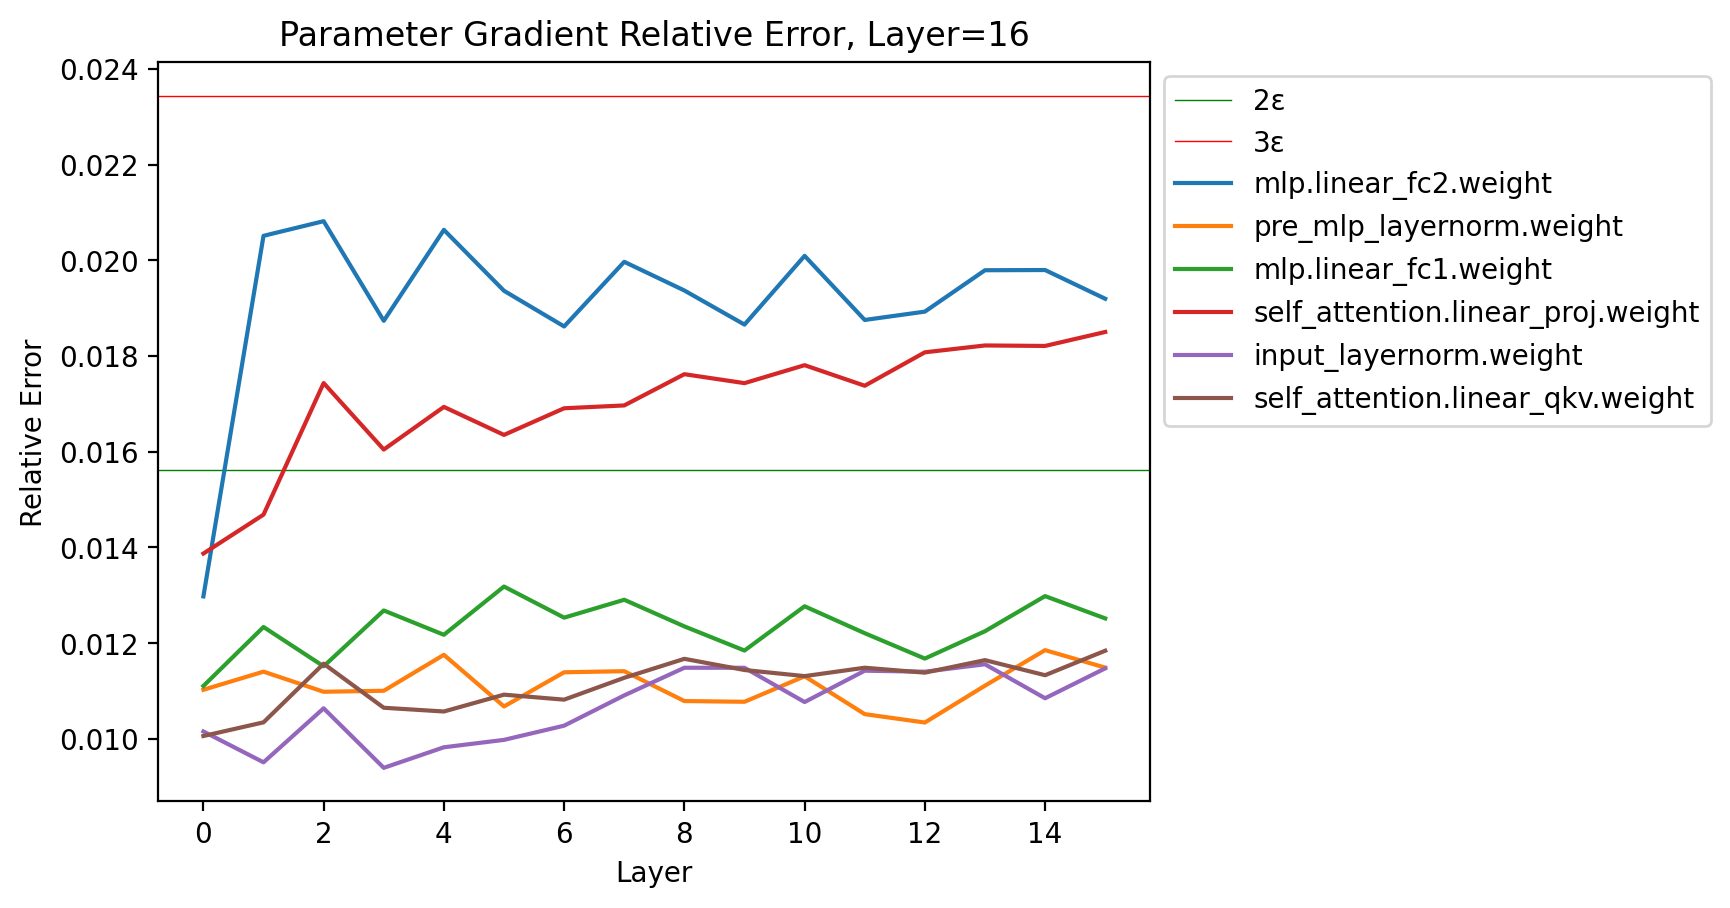

In [5]:
err_arr = neck.inspector.get_err_array(torch.load(neckruns/f"_single-v-tp{tp}--llama-e4m3/g_param.pt"), 4, L)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
plt.axhline(y=3*bf16, color='r', linestyle='-', linewidth=0.5, label='3ε')
for k, rerr in err_arr.items():
    plt.plot(range(L), rerr[1:].mean(axis=0), label=k)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Parameter Gradient Relative Error, Layer={L}")
plt.xlabel("Layer")
plt.ylabel("Relative Error")
plt.show()

In [7]:
import re
import numpy as np
from collections import defaultdict
def parse_main(name):
    pattern = r"iter\.0\|.*?layers\.(\d+)[\|\.](\S+)\|g_param_main"
    m = re.match(pattern, name)
    if m:
        layer_num = m.group(1)
        activation_name = m.group(2)
        return layer_num, activation_name
    else:
        return None, None

def get_err_array_main(err_dict, layer_num) -> dict[str, np.ndarray]:
    err_array_dict = defaultdict(lambda: np.zeros((layer_num,)))
    for name, err in err_dict.items():
        layer, activation_name = parse_main(name)
        if layer is None:
            continue
        err_array_dict[activation_name][int(layer)] = err
    return err_array_dict

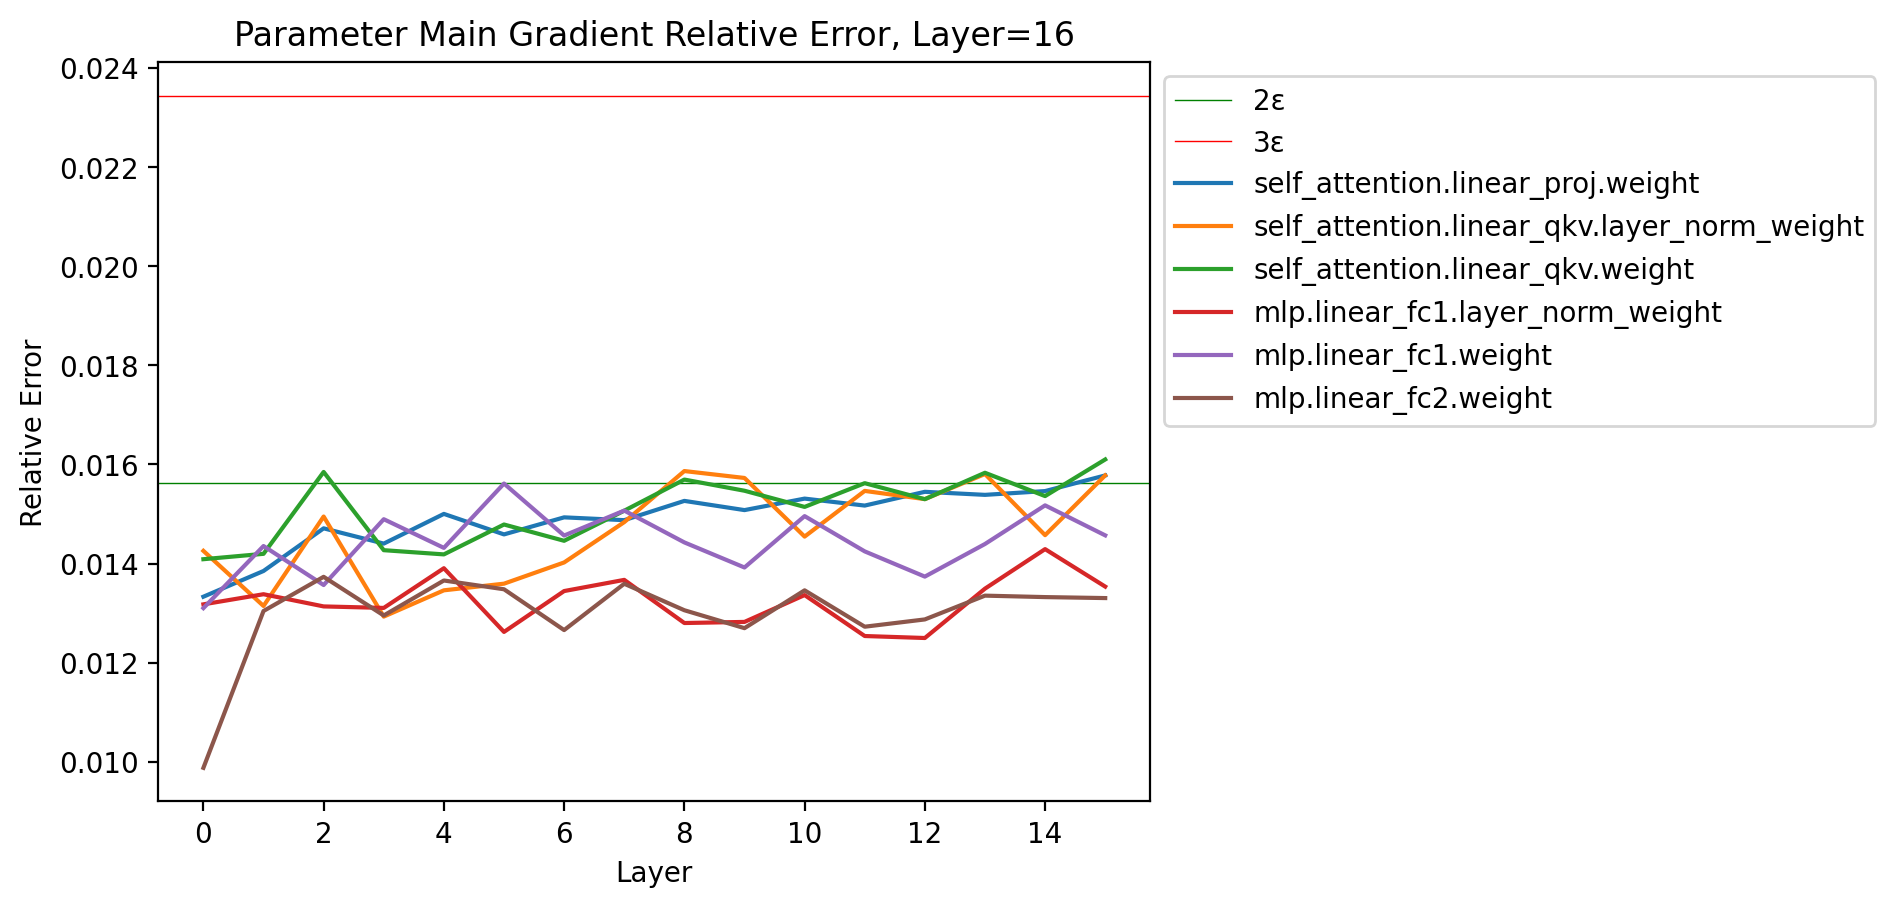

In [8]:
err_arr = get_err_array_main(torch.load(neckruns/f"_single-v-tp{tp}--llama-e4m3/g_param_main.pt"), L)
bf16 = 2**-7
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
import matplotlib.pyplot as plt
plt.axhline(y=2*bf16, color='g', linestyle='-', linewidth=0.5, label='2ε')
plt.axhline(y=3*bf16, color='r', linestyle='-', linewidth=0.5, label='3ε')
for k, rerr in err_arr.items():
    plt.plot(range(L), rerr, label=k)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.title(f"Parameter Main Gradient Relative Error, Layer={L}")
plt.xlabel("Layer")
plt.ylabel("Relative Error")
plt.show()